In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", None)

# --- Load ---
moh = pd.read_excel("Encounters to Diabetic Clinics MOH Hospitals.xlsx")
mos = pd.read_excel("data.xlsx")

In [2]:
# --- First look: MOH ---
print(moh.shape)
display(moh.head())
display(moh.tail(3))   
moh.info()

(21, 6)


,Saudi Male,Saudi female,Non-Saudi Male,Non-Saudi Female,Total,Health Region
0,30138,41254,4918,4162,80472,Riyadh
1,33194,42148,3942,2610,81894,The Holy Capital
2,4267,4804,383,321,9775,Jeddah
3,16574,19452,2536,1644,40206,Ta`if
4,10901,11333,729,588,23551,Medinah


,Saudi Male,Saudi female,Non-Saudi Male,Non-Saudi Female,Total,Health Region
18,6426,10271,919,852,18468,Qurrayat
19,1020,1580,13,3,2616,Qunfudah
20,254443,320324,24963,17647,617377,Total


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Saudi Male        21 non-null     int64
 1   Saudi female      21 non-null     int64
 2   Non-Saudi Male    21 non-null     int64
 3   Non-Saudi Female  21 non-null     int64
 4   Total             21 non-null     int64
 5   Health Region     21 non-null     str  
dtypes: int64(5), str(1)
memory usage: 1.3 KB


In [3]:
# --- First look: MOS ---
print(mos.shape)
display(mos.head())
mos.info()
print("Missing values:\n", mos.isna().sum())
print("Duplicate rows:", mos.duplicated().sum())

(773, 4)


,SubFacilityName,FacilityName,CityName,RegionName
0,صالة الرياضية - استاد الأمير فيصل بن فهد,استاد الامير فيصل بن فهد,الرياض,منطقة الرياض
1,مضمار - الملعب الرديف - استاد الأمير فيصل بن فهد,استاد الامير فيصل بن فهد,الرياض,منطقة الرياض
2,صالة رياضية ( B ) - استاد الأمير فيصل بن فهد,استاد الامير فيصل بن فهد,الرياض,منطقة الرياض
3,معلب عرقة - استاد الامير فيصل بن فهد,استاد الامير فيصل بن فهد,الرياض,منطقة الرياض
4,صالة الجمباز - استاد الأمير فيصل بن فهد,استاد الامير فيصل بن فهد,الرياض,منطقة الرياض


<class 'pandas.DataFrame'>
RangeIndex: 773 entries, 0 to 772
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   SubFacilityName  773 non-null    str  
 1   FacilityName     773 non-null    str  
 2   CityName         773 non-null    str  
 3   RegionName       773 non-null    str  
dtypes: str(4)
memory usage: 150.7 KB
Missing values:
 SubFacilityName    0
FacilityName       0
CityName           0
RegionName         0
dtype: int64
Duplicate rows: 3


In [4]:
# --- Basic cleaning ---
# MOH: rename columns to snake_case and drop the grand-total row
moh.columns = (moh.columns.str.strip().str.lower()
               .str.replace(" ", "_").str.replace("-", "_"))
moh = moh[moh["health_region"].str.strip().str.lower() != "total"].copy()
moh["health_region"] = moh["health_region"].str.strip()

# Sanity check: do the rows add up to the Total column?
print(moh.shape)   # expect 20 rows
print((moh[["saudi_male","saudi_female","non_saudi_male","non_saudi_female"]].sum(axis=1)
       == moh["total"]).all())

# MOS: drop exact duplicates
mos = mos.drop_duplicates().copy()
print(mos.shape)   # expect 770 rows

(20, 6)
True
(770, 4)


In [5]:
# --- Quick profile of each dataset ---
print(mos["RegionName"].value_counts())
print("\nFacilities:", mos["FacilityName"].nunique(), "| Cities:", mos["CityName"].nunique())

print(moh[["health_region","total"]].sort_values("total", ascending=False))

RegionName
المنطقة الشرقية          192
منطقة الرياض             176
منطقة مكة المكرمة        129
منطقة القصيم              69
منطقة المدينة المنورة     42
منطقة حائل                38
منطقة عسير                33
منطقة نجران               21
منطقة الباحة              18
منطقة جازان               17
منطقة تبوك                15
منطقة الجوف               11
منطقة الحدود الشمالية      9
Name: count, dtype: int64

Facilities: 70 | Cities: 31
       health_region  total
1   The Holy Capital  81894
9              Aseer  81356
0             Riyadh  80472
5             Qaseem  50902
14             Jazan  50330
3              Ta`if  40206
6            Eastern  27948
12             Ha`il  26700
4            Medinah  23551
15            Najran  21068
16          Al-Bahah  21016
18          Qurrayat  18468
13  Northern Borders  16095
10            Bishah  15131
17           Al-Jouf  14534
11            Tabouk  12720
8      Hafr Al-Baten  12707
7            Al-Ahsa   9888
2             Jeddah   97

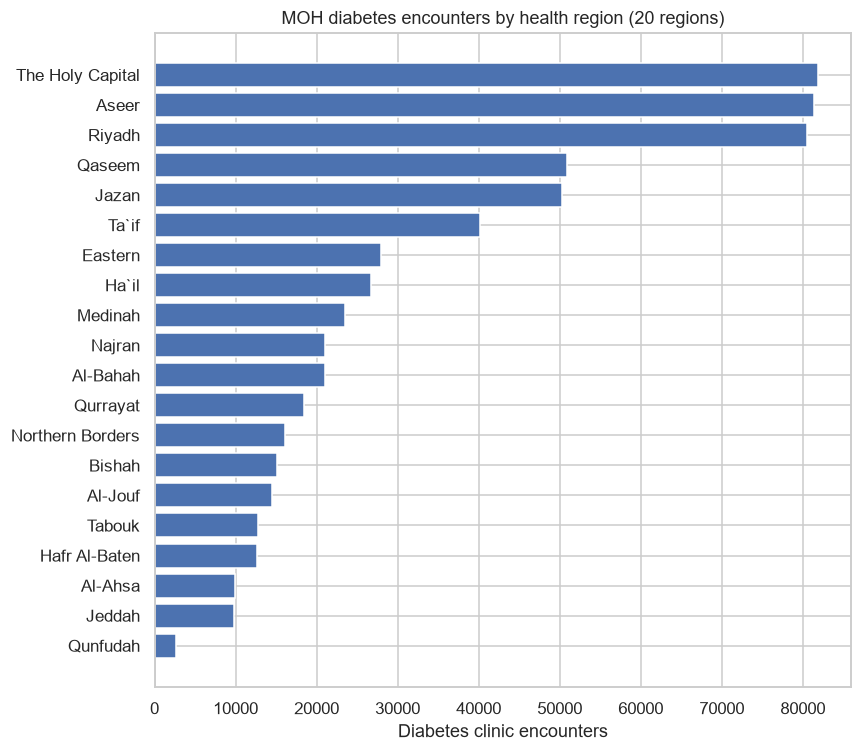

In [6]:
order = moh.sort_values("total")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(order["health_region"], order["total"])
ax.set_xlabel("Diabetes clinic encounters")
ax.set_title("MOH diabetes encounters by health region (20 regions)")
plt.tight_layout()
plt.show()

In [7]:
# MOH health region -> administrative region
moh_map = {
    "Riyadh": "Riyadh",
    "The Holy Capital": "Makkah", "Jeddah": "Makkah", "Ta`if": "Makkah", "Qunfudah": "Makkah",
    "Medinah": "Madinah",
    "Qaseem": "Qassim",
    "Eastern": "Eastern", "Al-Ahsa": "Eastern", "Hafr Al-Baten": "Eastern",
    "Aseer": "Aseer", "Bishah": "Aseer",
    "Tabouk": "Tabuk",
    "Ha`il": "Hail",
    "Northern Borders": "Northern Borders",
    "Jazan": "Jazan",
    "Najran": "Najran",
    "Al-Bahah": "Al-Baha",
    "Al-Jouf": "Al-Jouf", "Qurrayat": "Al-Jouf",
}

# MOS Arabic region name -> same English names
mos_map = {
    "منطقة الرياض": "Riyadh",
    "منطقة مكة المكرمة": "Makkah",
    "منطقة المدينة المنورة": "Madinah",
    "منطقة القصيم": "Qassim",
    "المنطقة الشرقية": "Eastern",
    "منطقة عسير": "Aseer",
    "منطقة تبوك": "Tabuk",
    "منطقة حائل": "Hail",
    "منطقة الحدود الشمالية": "Northern Borders",
    "منطقة جازان": "Jazan",
    "منطقة نجران": "Najran",
    "منطقة الباحة": "Al-Baha",
    "منطقة الجوف": "Al-Jouf",
}

moh["region"] = moh["health_region"].map(moh_map)
mos["region"] = mos["RegionName"].str.strip().map(mos_map)

# Safety check: nothing should be left unmapped
print("Unmapped MOH:", moh.loc[moh["region"].isna(), "health_region"].tolist())
print("Unmapped MOS:", mos.loc[mos["region"].isna(), "RegionName"].unique().tolist())

Unmapped MOH: []
Unmapped MOS: []


In [8]:
moh_region = (moh.groupby("region", as_index=False)
                 [["saudi_male", "saudi_female", "non_saudi_male", "non_saudi_female", "total"]]
                 .sum()
                 .rename(columns={"total": "diabetes_encounters"}))

mos_region = (mos.groupby("region", as_index=False)
                 .agg(sub_facilities=("SubFacilityName", "count"),
                      facilities=("FacilityName", "nunique"),
                      cities=("CityName", "nunique")))

print(moh_region.shape, mos_region.shape)   # both should be (13, ...)

(13, 6) (13, 4)


In [9]:
df = moh_region.merge(mos_region, on="region", how="outer", validate="one_to_one", indicator=True)

print(df["_merge"].value_counts())   
df = df.drop(columns="_merge")
df

_merge
both          13
left_only      0
right_only     0
Name: count, dtype: int64


,region,saudi_male,saudi_female,non_saudi_male,non_saudi_female,diabetes_encounters,sub_facilities,facilities,cities
0,Al-Baha,9885,11010,80,41,21016,18,1,1
1,Al-Jouf,12455,18776,919,852,33002,11,2,1
2,Aseer,44126,51040,795,526,96487,33,3,2
3,Eastern,20786,27095,1421,1241,50543,192,17,8
4,Hail,9848,15960,468,424,26700,38,3,1
5,Jazan,22674,24698,1763,1195,50330,17,1,1
6,Madinah,10901,11333,729,588,23551,42,3,1
7,Makkah,55055,67984,6874,4578,134491,129,9,3
8,Najran,7591,9643,2379,1455,21068,21,2,1
9,Northern Borders,6607,5234,2984,1270,16095,9,1,1


In [10]:
print(df["diabetes_encounters"].sum())

617377


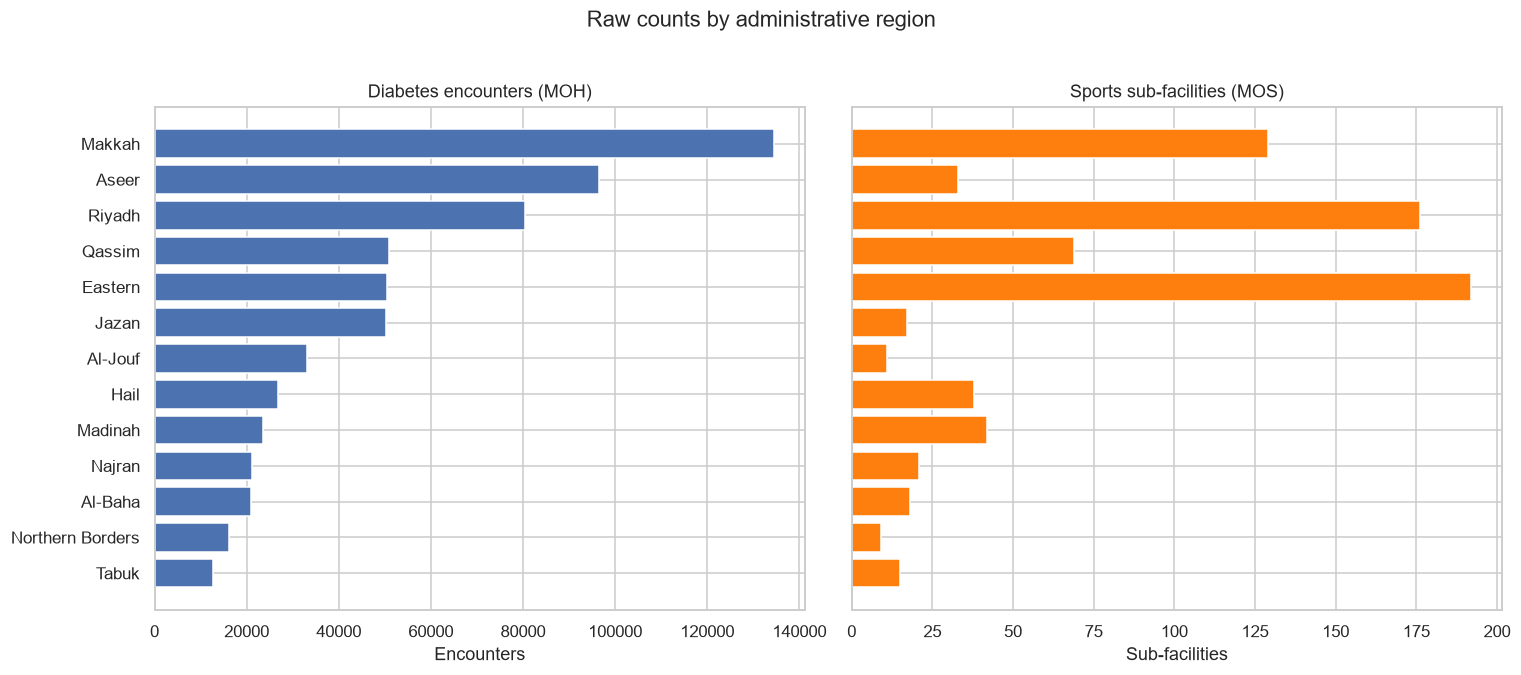

In [11]:
d = df.sort_values("diabetes_encounters")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axes[0].barh(d["region"], d["diabetes_encounters"])
axes[0].set_title("Diabetes encounters (MOH)")
axes[0].set_xlabel("Encounters")

axes[1].barh(d["region"], d["sub_facilities"], color="tab:orange")
axes[1].set_title("Sports sub-facilities (MOS)")
axes[1].set_xlabel("Sub-facilities")

plt.suptitle("Raw counts by administrative region", y=1.02)
plt.tight_layout()
plt.show()

In [12]:
from scipy import stats

pairs = [("sub_facilities", "diabetes_encounters"),
         ("facilities", "diabetes_encounters")]

for x, y in pairs:
    r, p = stats.pearsonr(df[x], df[y])
    rho, p_s = stats.spearmanr(df[x], df[y])
    print(f"{x} vs {y}")
    print(f"  Pearson  r   = {r:.2f} (p = {p:.3f})")
    print(f"  Spearman rho = {rho:.2f} (p = {p_s:.3f})\n")

sub_facilities vs diabetes_encounters
  Pearson  r   = 0.56 (p = 0.046)
  Spearman rho = 0.67 (p = 0.012)

facilities vs diabetes_encounters
  Pearson  r   = 0.49 (p = 0.092)
  Spearman rho = 0.71 (p = 0.007)



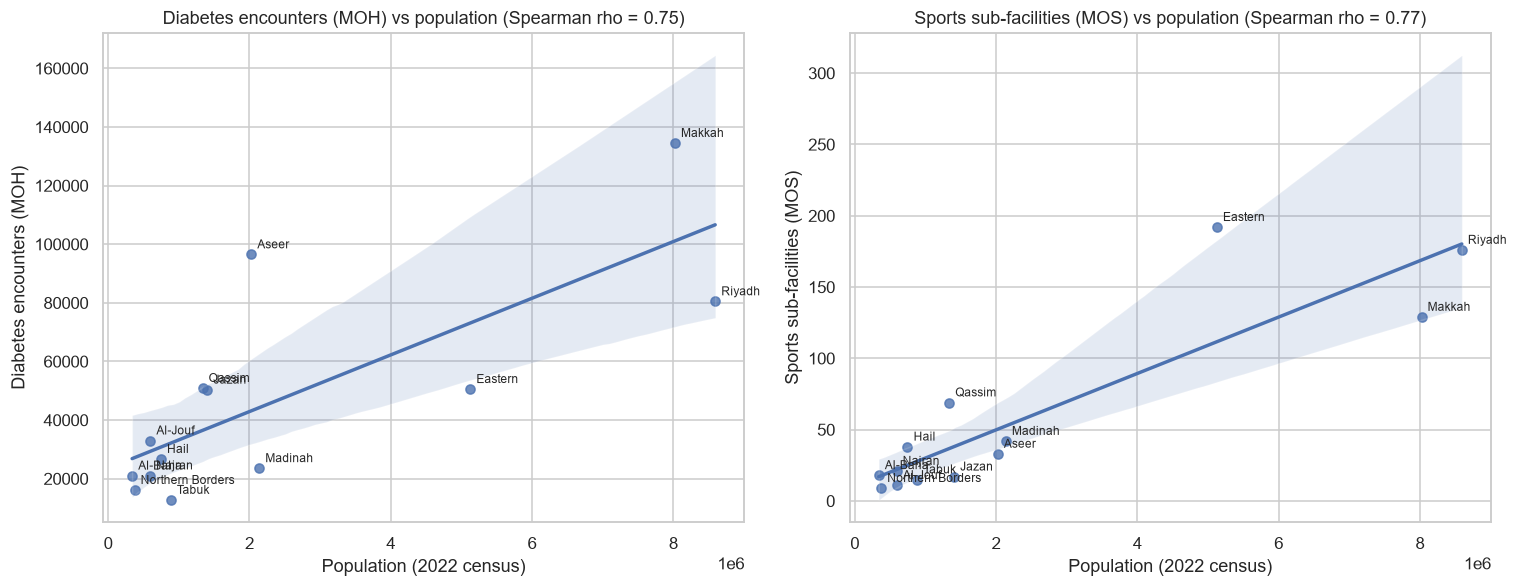

Missing populations: 0
Pearson r = 0.31 (p = 0.302) | Spearman rho = 0.13 (p = 0.681)


,region,population,encounters_per_1000,facilities_per_100k
0,Al-Baha,339174.0,62.0,5.3
1,Al-Jouf,595822.0,55.4,1.8
2,Aseer,2024285.0,47.7,1.6
3,Eastern,5125254.0,9.9,3.7
4,Hail,746406.0,35.8,5.1
5,Jazan,1404997.0,35.8,1.2
6,Madinah,2137983.0,11.0,2.0
7,Makkah,8021463.0,16.8,1.6
8,Najran,592300.0,35.6,3.5
9,Northern Borders,373577.0,43.1,2.4


In [13]:
population = {
    "Riyadh": 8_591_748,
    "Makkah": 8_021_463,
    "Eastern": 5_125_254,
    "Madinah": 2_137_983,
    "Aseer": 2_024_285,
    "Jazan": 1_404_997,
    "Qassim": 1_336_179,
    "Tabuk": 886_036,
    "Hail": 746_406,
    "Al-Jouf": 595_822,
    "Najran": 592_300,
    "Northern Borders": 373_577,
    "Al-Baha": 339_174,
}

assert sum(population.values()) == 32_175_224   # matches the census national total

df["population"] = df["region"].map(population).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
panels = [("diabetes_encounters", "Diabetes encounters (MOH)"),
          ("sub_facilities", "Sports sub-facilities (MOS)")]

for ax, (col, label) in zip(axes, panels):
    sns.regplot(data=df, x="population", y=col, ax=ax)
    for _, row in df.iterrows():
        ax.annotate(row["region"], (row["population"], row[col]),
                    textcoords="offset points", xytext=(4, 4), fontsize=8)
    rho, _ = stats.spearmanr(df["population"], df[col])
    ax.set_title(f"{label} vs population (Spearman rho = {rho:.2f})")
    ax.set_xlabel("Population (2022 census)")
    ax.set_ylabel(label)

plt.tight_layout()
plt.show()
print("Missing populations:", df["population"].isna().sum())   # should be 0

df["encounters_per_1000"] = df["diabetes_encounters"] / df["population"] * 1000
df["facilities_per_100k"] = df["sub_facilities"] / df["population"] * 100_000

r, p = stats.pearsonr(df["facilities_per_100k"], df["encounters_per_1000"])
rho, p_s = stats.spearmanr(df["facilities_per_100k"], df["encounters_per_1000"])
print(f"Pearson r = {r:.2f} (p = {p:.3f}) | Spearman rho = {rho:.2f} (p = {p_s:.3f})")

df[["region", "population", "encounters_per_1000", "facilities_per_100k"]].round(1)

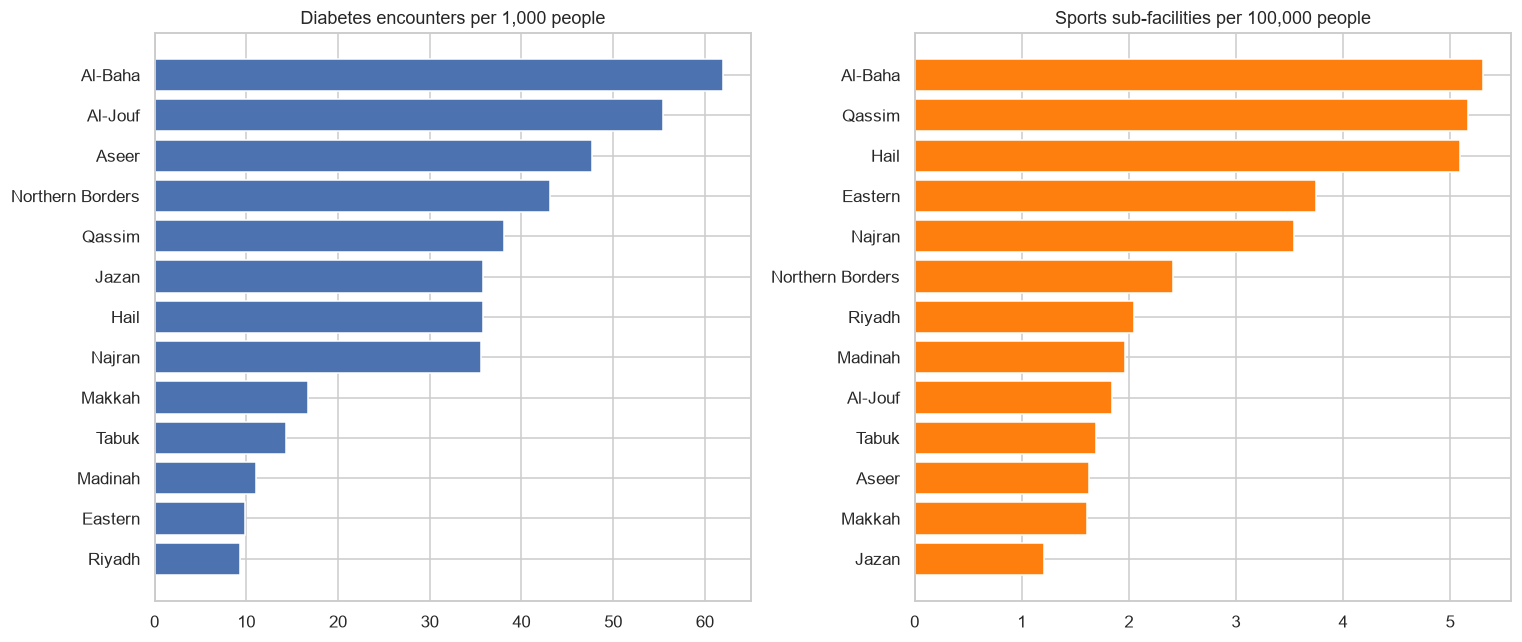

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

a = df.sort_values("encounters_per_1000")
axes[0].barh(a["region"], a["encounters_per_1000"])
axes[0].set_title("Diabetes encounters per 1,000 people")

b = df.sort_values("facilities_per_100k")
axes[1].barh(b["region"], b["facilities_per_100k"], color="tab:orange")
axes[1].set_title("Sports sub-facilities per 100,000 people")

plt.tight_layout()
plt.show()

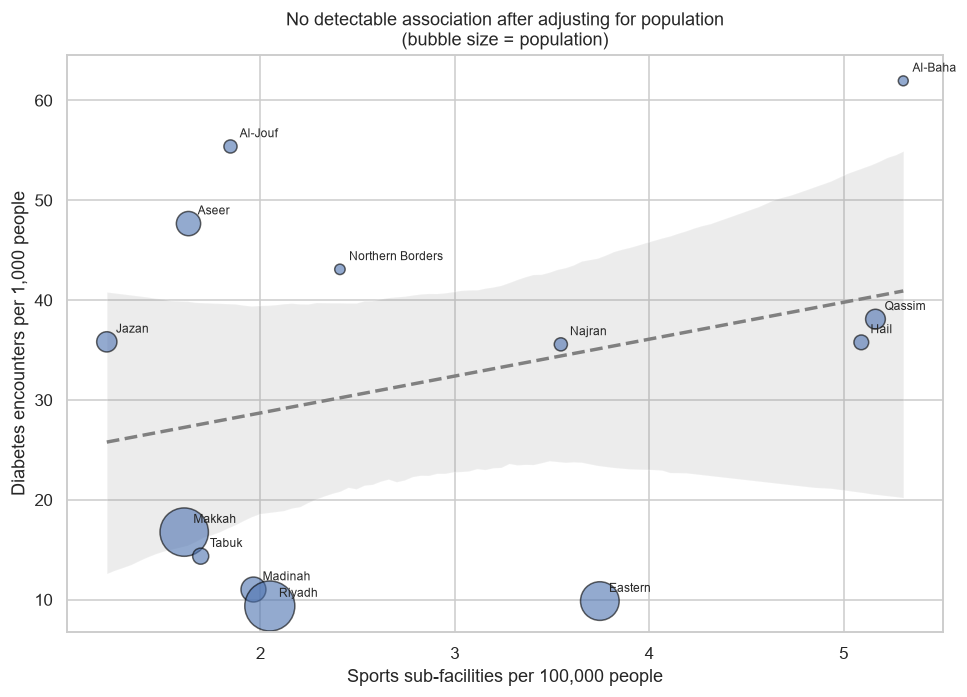

In [15]:
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.regplot(data=df, x="facilities_per_100k", y="encounters_per_1000",
            scatter=False, ax=ax, color="gray", line_kws={"linestyle": "--"})
ax.scatter(df["facilities_per_100k"], df["encounters_per_1000"],
           s=df["population"] / 8000, alpha=0.6, edgecolor="black")
for _, row in df.iterrows():
    ax.annotate(row["region"], (row["facilities_per_100k"], row["encounters_per_1000"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8)

ax.set_xlabel("Sports sub-facilities per 100,000 people")
ax.set_ylabel("Diabetes encounters per 1,000 people")
ax.set_title("No detectable association after adjusting for population\n"
             "(bubble size = population)")
plt.tight_layout()
plt.show()

In [16]:
sub = df[~df["region"].isin(["Makkah", "Madinah"])]
r, p = stats.pearsonr(sub["facilities_per_100k"], sub["encounters_per_1000"])
rho, p_s = stats.spearmanr(sub["facilities_per_100k"], sub["encounters_per_1000"])
print(f"Without Makkah/Madinah (n={len(sub)}): r = {r:.2f} (p = {p:.3f}), rho = {rho:.2f} (p = {p_s:.3f})")

Without Makkah/Madinah (n=11): r = 0.20 (p = 0.548), rho = 0.09 (p = 0.790)


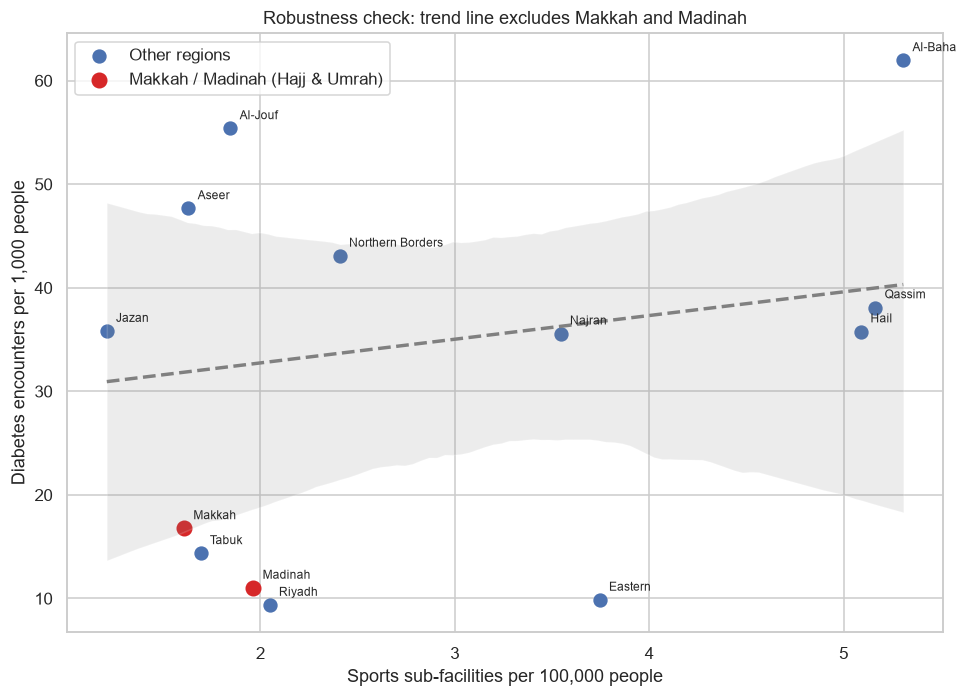

In [17]:
fig, ax = plt.subplots(figsize=(9, 6.5))
flag = df["region"].isin(["Makkah", "Madinah"])

ax.scatter(df.loc[~flag, "facilities_per_100k"], df.loc[~flag, "encounters_per_1000"],
           s=70, label="Other regions")
ax.scatter(df.loc[flag, "facilities_per_100k"], df.loc[flag, "encounters_per_1000"],
           s=90, color="tab:red", label="Makkah / Madinah (Hajj & Umrah)")
for _, row in df.iterrows():
    ax.annotate(row["region"], (row["facilities_per_100k"], row["encounters_per_1000"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8)

sns.regplot(data=df[~flag], x="facilities_per_100k", y="encounters_per_1000",
            scatter=False, ax=ax, color="gray", line_kws={"linestyle": "--"})
ax.set_xlabel("Sports sub-facilities per 100,000 people")
ax.set_ylabel("Diabetes encounters per 1,000 people")
ax.set_title("Robustness check: trend line excludes Makkah and Madinah")
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
print(df[["region", "encounters_per_1000", "facilities_per_100k"]]
      .sort_values("encounters_per_1000", ascending=False).round(1))

              region  encounters_per_1000  facilities_per_100k
0            Al-Baha                 62.0                  5.3
1            Al-Jouf                 55.4                  1.8
2              Aseer                 47.7                  1.6
9   Northern Borders                 43.1                  2.4
10            Qassim                 38.1                  5.2
5              Jazan                 35.8                  1.2
4               Hail                 35.8                  5.1
8             Najran                 35.6                  3.5
7             Makkah                 16.8                  1.6
12             Tabuk                 14.4                  1.7
6            Madinah                 11.0                  2.0
3            Eastern                  9.9                  3.7
11            Riyadh                  9.4                  2.0


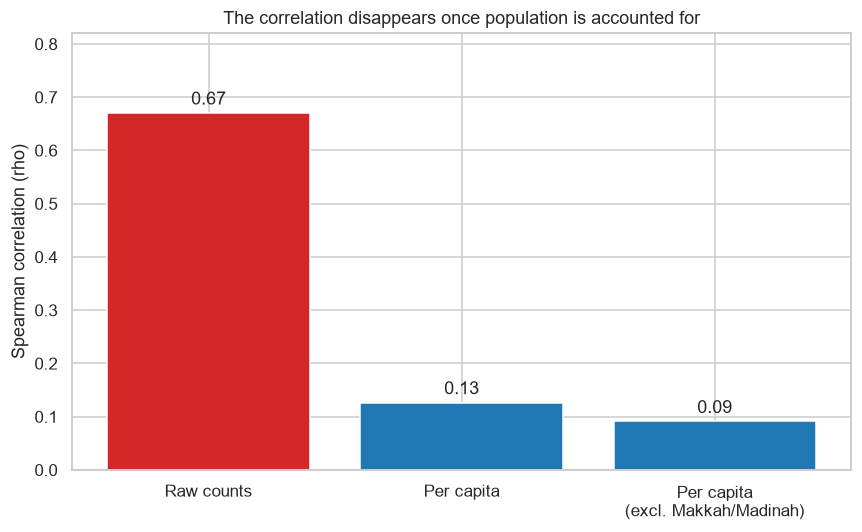

In [19]:
rho_raw, _ = stats.spearmanr(df["sub_facilities"], df["diabetes_encounters"])
rho_pc, _ = stats.spearmanr(df["facilities_per_100k"], df["encounters_per_1000"])
sub = df[~df["region"].isin(["Makkah", "Madinah"])]
rho_sub, _ = stats.spearmanr(sub["facilities_per_100k"], sub["encounters_per_1000"])

summary = pd.DataFrame({
    "analysis": ["Raw counts", "Per capita", "Per capita\n(excl. Makkah/Madinah)"],
    "spearman_rho": [rho_raw, rho_pc, rho_sub],
})

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(summary["analysis"], summary["spearman_rho"],
              color=["tab:red", "tab:blue", "tab:blue"])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(min(0, summary["spearman_rho"].min() - 0.05), summary["spearman_rho"].max() + 0.15)
ax.set_ylabel("Spearman correlation (rho)")
ax.set_title("The correlation disappears once population is accounted for")
plt.tight_layout()
plt.show()